# 33.44. Измеренный пульс ТТРКГ, объёмная чувствительность и камеры КТ

**Исследовательский результат.** На Георгии, Нике и Ярославе сопоставлены по четыре
последовательных ЭКГ-интервала на глубоком вдохе с индивидуальной объёмной
чувствительностью ТТРКГ. Изменение объёма однородной сферы в рассчитанном
диапазоне ±5% не воспроизводит измеренный пульсовой размах ни в одном из двух
материальных профилей. Знак ответа зависит от профиля; для одного случая
ответ немонотонен. Получить из этого сопоставления проверенный ударный объём нельзя.

На динамической КТ Георгия и Ника дополнительно проверяется связь изменения
объёма всего сердца с камерными объёмами. Для Ярослава такой серии пока нет
(подтверждение автора 28.10.2026). КТ и Scorpion зарегистрированы в разных
сессиях: здесь нет синхронной проверки отдельного сокращения.

Статус разметки — кандидатный, `pending_manual_review`. Это ограничивает
интерпретацию и не меняется при успешном исполнении ноутбука. Цель работы —
проверить применимость перехода «пульс ТТРКГ → объём эквивалентной модели →
камерные объёмы», сохранив отрицательные результаты каждого перехода.

In [1]:
import json
from pathlib import Path
import build_measured_pulse_report as F
from IPython.display import HTML, display
S=F.verify_summary()

## 1. Какие измерения сравниваются

Для всех трёх участников выбран один и тот же монтаж: ТТРКГ 2×2 на руках
при установленной боковой сборке 140 мм. Это основной монтаж выполненного
объёмного FEM-теста; коэффициенты этого теста не переносятся на 1×1 и 1×4.
ТТРКГ взята из записи 003 Георгия и записей 001 Ника и Ярослава. У Георгия
и Ника это физический канал 1, у Ярослава — канал 2. Выбор основан на
протоколе и проверке назначения отведений, а не на амплитуде импеданса.

Пять сохранённых кандидатных QRS-событий ограничивают четыре полных R–R.
Интервалы взяты из существующих артефактов этапов 11.20 и 11.40; новые
дыхательные границы и R-зубцы не определялись. Четыре цикла выбраны
в центральной части реконструированной задержки вдоха по ЭКГ и времени,
без отбора по амплитуде ТТРКГ. Границы задержки восстановлены ретроспективно;
прибор не записывал метки дыхательных команд.

Используется сохранённая пульсовая полоса 0,7–12 Гц: фильтр Баттерворта
четвёртого порядка применён без фазового сдвига к полной записи, затем
вырезан участок. ЭКГ подавляет 50, 100 и 150 Гц и ограничена полосой
0,5–40 Гц. Рабочая дискретизация — 1000 Гц, зондирование — 100 кГц.
Для Георгия временная шкала дополнительно связана с BIN; для Ника и Ярослава
использована сохранённая проверка сессии. Пульс показан в мОм, ЭКГ — в мВ.
Знак сохранён; амплитудная нормировка, подбор усиления и задержки отсутствуют.

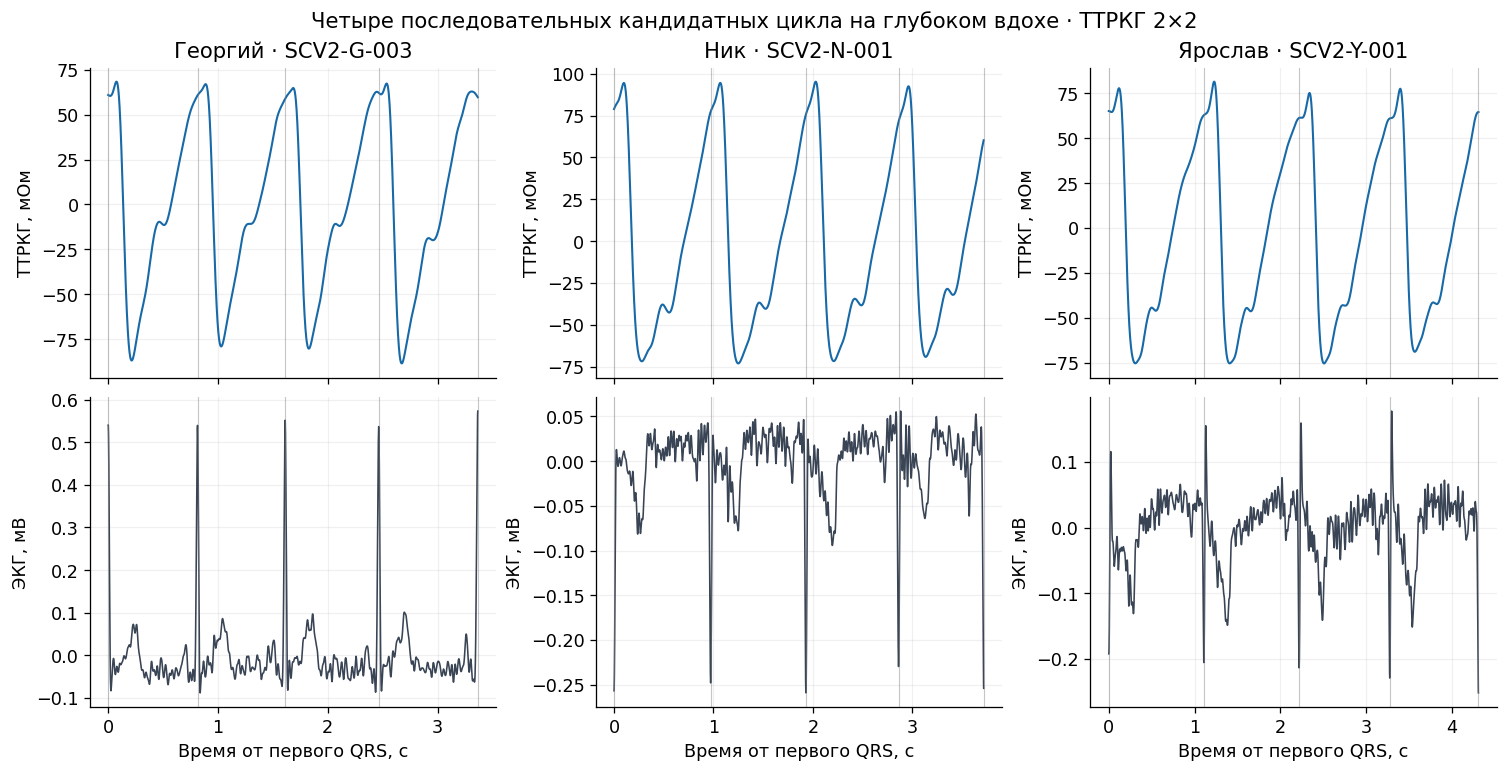

Участник,Запись,Цикл,"Начало, с","Конец, с","R–R, с","Размах, мОм","Минимум от R, мОм","Максимум от R, мОм"
Георгий,SCV2-G-003,1,35.057,35.871,0.814,155.108,-147.719,7.38823
Георгий,SCV2-G-003,2,35.871,36.669,0.798,145.89,-139.623,6.26776
Георгий,SCV2-G-003,3,36.669,37.521,0.852,144.979,-138.948,6.03154
Георгий,SCV2-G-003,4,37.521,38.424,0.903,155.691,-150.535,5.15686
Ник,SCV2-N-001,1,24.45,25.422,0.972,166.284,-150.67,15.6135
Ник,SCV2-N-001,2,25.422,26.38,0.958,167.574,-150.445,17.1295
Ник,SCV2-N-001,3,26.38,27.312,0.932,166.937,-147.393,19.5441
Ник,SCV2-N-001,4,27.312,28.168,0.856,161.683,-140.512,21.1711
Ярослав,SCV2-Y-001,1,26.49,27.599,1.109,152.905,-140.216,12.6889
Ярослав,SCV2-Y-001,2,27.599,28.709,1.11,156.584,-137.974,18.6103


In [2]:
F.show_figure(S,1)
display(HTML(F.pulse_table(S)))

**Рисунок 1.** ТТРКГ и ЭКГ на четырёх последовательных интервалах.
Вертикальные линии — существующие кандидатные QRS, начало шкалы совпадает
с первым из них. Это отдельные записи, а не синхронная регистрация трёх людей.

**Наблюдение:** Георгий: 145.0–155.7 мОм; Ник: 161.7–167.6 мОм; Ярослав: 146.2–156.6 мОм. Различия четырёх циклов показывают
внутриучастковую вариабельность; они не являются доверительным интервалом
межсессионной воспроизводимости. Размах не содержит собственного знака.
Для проверки направления изменения в таблице 1 отдельно приведены минимум
и максимум относительно отсчёта у начального QRS. Эта нулевая точка не
объявляется концом диастолы или механическим началом изгнания. Во всех
выбранных циклах максимум расположен примерно на 8–12% R–R, минимум —
на 23–32% R–R. Названия механических фаз этим экстремумам не назначены.

## 2. Что означает объёмная чувствительность

Конечноэлементная модель каждого участника использует его собственную
КТ-геометрию и сегментированные поверхности TotalSegmentator 2.18.
Учтены мягкотканный фон, лёгкие, кости, сердце и жир. Руки представлены
цилиндрами с обхватом 37 см (для Ярослава — приблизительное значение).
Контакты моделируются дисками диаметром 5 мм с контактным импедансом
0,01 Ом·м²; это заданное условие, а не измерение контакта.

Автор подтвердил временное разделение каналов Scorpion. Поэтому используется
отклик ТТРКГ от собственного токового источника, T(2,1), без суммы двух
токов и без межканальной фазы. Около 7 мА на источник не являются
множителем уже рассчитанного импеданса в Омах.

Для сферы с неподвижным центром рассчитаны три объёма: 0,95V₀, V₀ и 1,05V₀,
где V₀ — объём маски всего сердца. Остальные ткани и контакты фиксированы.
Изменяется вся однородная сердечная область, а не отдельно кровь ЛЖ.
Конечная секущая определяется как

**kV = [Z(1,05V₀) − Z(0,95V₀)] / (0,10V₀), Ом/мл.**

Дополнительно проверяются секущие слева и справа от V₀. Совпадение их знаков
нужно для однозначного направления пересчёта в трёх рассчитанных точках;
оно не доказывает линейности на непрерывном интервале. Контроли q1024 и
q4096 изменяют квадратуру тканевых долей на той же сетке. Это не тест
сходимости сетки и не тест сходимости производной по шагу объёма.

Профиль с эффективным сердцем использует ρ мягкого фона/лёгких/костей/сердца/жира
**2,763586 / 9,315253 / 48,097674 / 4,648809 / 23,040605 Ом·м**.
Профиль «сердце как кровь» использует
**2,5 / 7 / 48,097674 / 1,35 / 23,040605 Ом·м**.
Значения костей и жира фиксированы по реестру при 100 кГц. Фон — эффективная
смесь невыделенных тканей, а не чистая мышца. Назначение 1,35 всему сердцу —
авторский сценарий без выделения миокарда и полостей. Между профилями
одновременно изменены три ρ; их разность нельзя приписать только ρ крови.

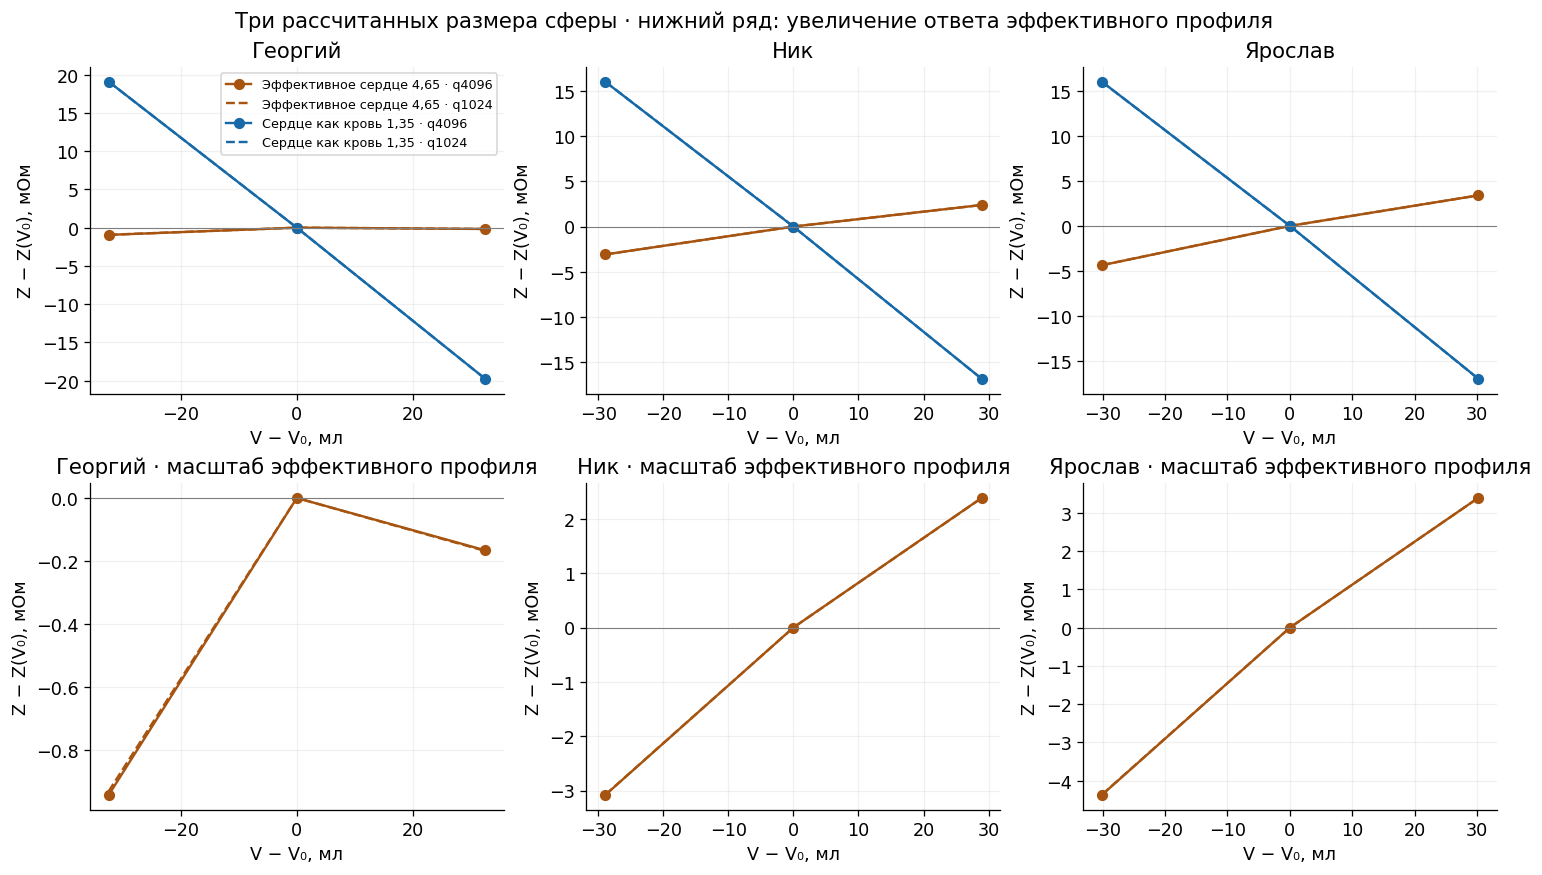

Участник,Профиль,"V₀, мл","0,10V₀, мл","kV, мОм/мл","Левая секущая, мОм/мл","Правая секущая, мОм/мл","δq kV, мОм/мл","Размах трёх FEM-точек, мОм","Пульс / размах FEM, мин–макс","Условный размах ΔVэкв, мл",В пределах проверенного диапазона
Георгий,"Эффективное сердце 4,65",650.459,65.0459,0.0119417,0.0289826,-0.00509932,0.000215226,0.942602,153.81–165.17,Заблокирован: немонотонность,Нет
Георгий,"Сердце как кровь 1,35",650.459,65.0459,-0.596661,-0.586792,-0.60653,7.57875e-05,38.8104,3.74–4.01,243.0–260.9,Нет
Ник,"Эффективное сердце 4,65",578.438,57.8438,0.094553,0.106637,0.0824691,0.000107564,5.46931,29.56–30.64,1710.0–1772.3,Нет
Ник,"Сердце как кровь 1,35",578.438,57.8438,-0.567564,-0.553747,-0.581382,0.000179744,32.8301,4.92–5.10,284.9–295.3,Нет
Ярослав,"Эффективное сердце 4,65",602.958,60.2958,0.128676,0.145055,0.112297,0.00012755,7.75863,18.84–20.18,1136.2–1216.9,Нет
Ярослав,"Сердце как кровь 1,35",602.958,60.2958,-0.547036,-0.531611,-0.562461,0.000210176,32.984,4.43–4.75,267.3–286.2,Нет


In [3]:
F.show_figure(S,2)
display(HTML(F.model_table(S)))

**Рисунок 2.** Ответ трёх размеров сферы относительно номинального размера.
Сплошные линии — q4096, штриховые — q1024. Отрезки между точками служат
для чтения графика; дополнительных размеров FEM не считали. Нижний ряд
показывает эффективный профиль в увеличенном масштабе: у Георгия видна
смена направления по обе стороны V₀.

**Результат модели:** у Ника и Ярослава увеличение объёма даёт положительное
ΔZ в профиле с эффективным сердцем и отрицательное ΔZ в профиле «сердце как
кровь». У Георгия в первом профиле Z растёт до V₀ и затем уменьшается:
левая и правая секущие имеют противоположные знаки в обеих квадратурах.
Единственный коэффициент между крайними размерами скрывает эту немонотонность.
Обратный пересчёт такого случая заблокирован. В кровяном профиле у всех
трёх увеличение сферы понижает импеданс. Это направление модельного ответа;
знак пульсового изменения объёма ещё требует связи с механическими фазами.

## 3. Совместим ли измеренный размах с объёмным тестом

Сначала сравнивается размах каждого измеренного R–R с размахом трёх
реально рассчитанных FEM-ответов. Такая проверка не требует назначать
начальному QRS камерный объём. Если измеренный размах больше модельного,
он не укладывается в изображение трёх проверенных состояний.

Для монотонных трёх точек дополнительно вычислен диагностический
**размах ΔVэкв = размах ΔZ / |kV|**. Это линейная экстраполяция, когда он
превышает 0,10V₀; она не является проверенным восстановлением объёма.
Для немонотонного случая число не выдаётся. Этот тест пока относится
к пульсу всего отведения: тканевые пульсовые вклады из него не вычитались.

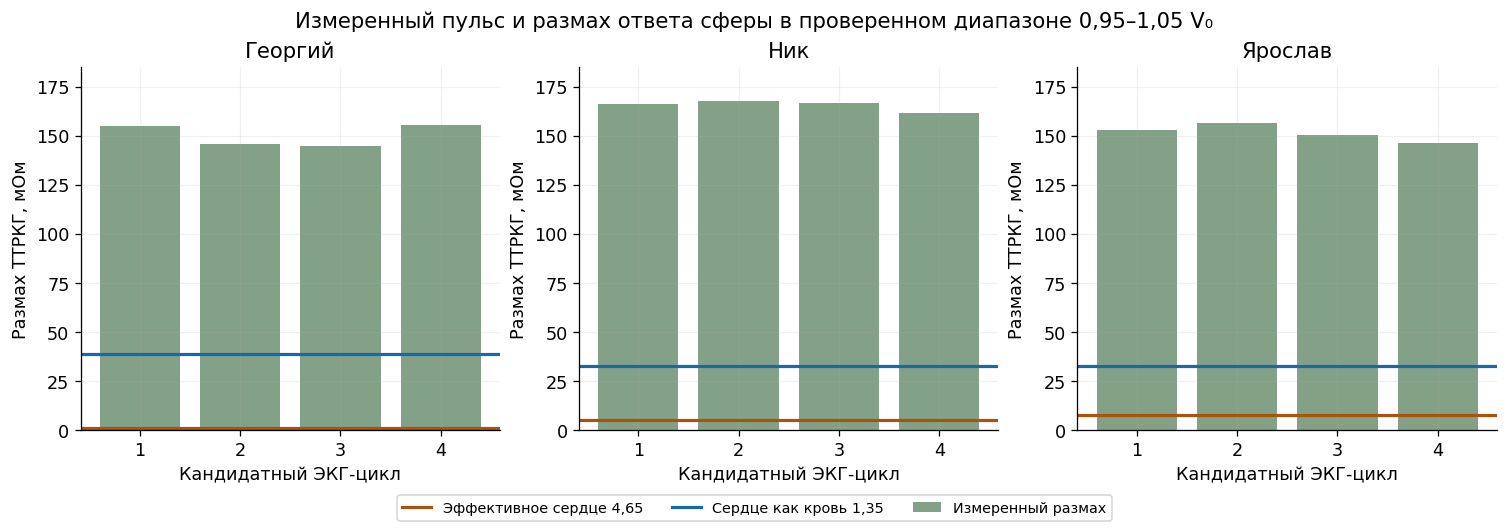

In [4]:
F.show_figure(S,3)

**Рисунок 3.** Столбцы — размах каждого измеренного цикла; горизонтальные
линии — размах ответа в диапазоне 0,95–1,05V₀. Обе материальные постановки
дают меньший размах, чем измеренный пульс, во всех двенадцати интервалах.
Это отрицательный результат ограниченной однородной модели с фиксированным
центром и фоном, а не доказательство отсутствия сердечного вклада в ТТРКГ.

В кровяном профиле линейная экстраполяция даёт: Георгий — 243–261 мл; Ник — 285–295 мл; Ярослав — 267–286 мл.
Проверенный полный диапазон составляет лишь 58–65 мл. В эффективном профиле
у Ника и Ярослава экстраполированные размахи ещё больше; у Георгия обратный
переход неоднозначен. Полученные числа не называются УО: меняется объём всего
сердца, а сигнал содержит также неразделённые тканевые и сосудистые вклады.

## 4. Как объём всего сердца связан с камерными объёмами на КТ

Динамика взята из сохранённой таблицы TotalSegmentator 2.18: маска всего
сердца получена задачей `total/heart`, кровь четырёх камер —
`heartchambers_highres`. Эти маски кандидатные и не прошли независимую
анатомическую валидацию. При этом исследовании маски не пересегментировались.
Камерные объёмы рассчитаны по исходным маскам без пересечения с маской
всего сердца; их сумма потому не обязана заполнять её точно. Объём остатка
«сердце минус кровь» также не является референсным полным миокардом.

Временная ось основана на R-триггерах GE, а не на цифровой ЭКГ Scorpion.
У Георгия имеются два несовместимых по длительности интервала — 491 и
1159 мс. Их причина не разрешена; интервалы не объединяются и не растягиваются
к одному R–R. У Ника также показаны два собственных интервала, включая
второй с тремя доступными фазами. Замыкание недостающего конца цикла,
поиск КДО/КСО и вычисление УО/ФВ здесь не выполняются.

Проверяется простая гипотеза: равняется ли межкадровое изменение объёма
всего сердца изменению ЛЖ, ПЖ или сумм камер. Для каждой соседней пары фаз
внутри одного R–R вычисляются ΔV и сравниваются знаки, корреляция и
RMSE относительно тождества ΔVцел = ΔVкам. Корреляция здесь описательная:
кадров мало, они зависимы, интервалы неопределённости сегментации неизвестны.
Для двух пар корреляция не приводится. Начальная фаза каждого графика
служит лишь точкой отсчёта, а не принятым концом диастолы.

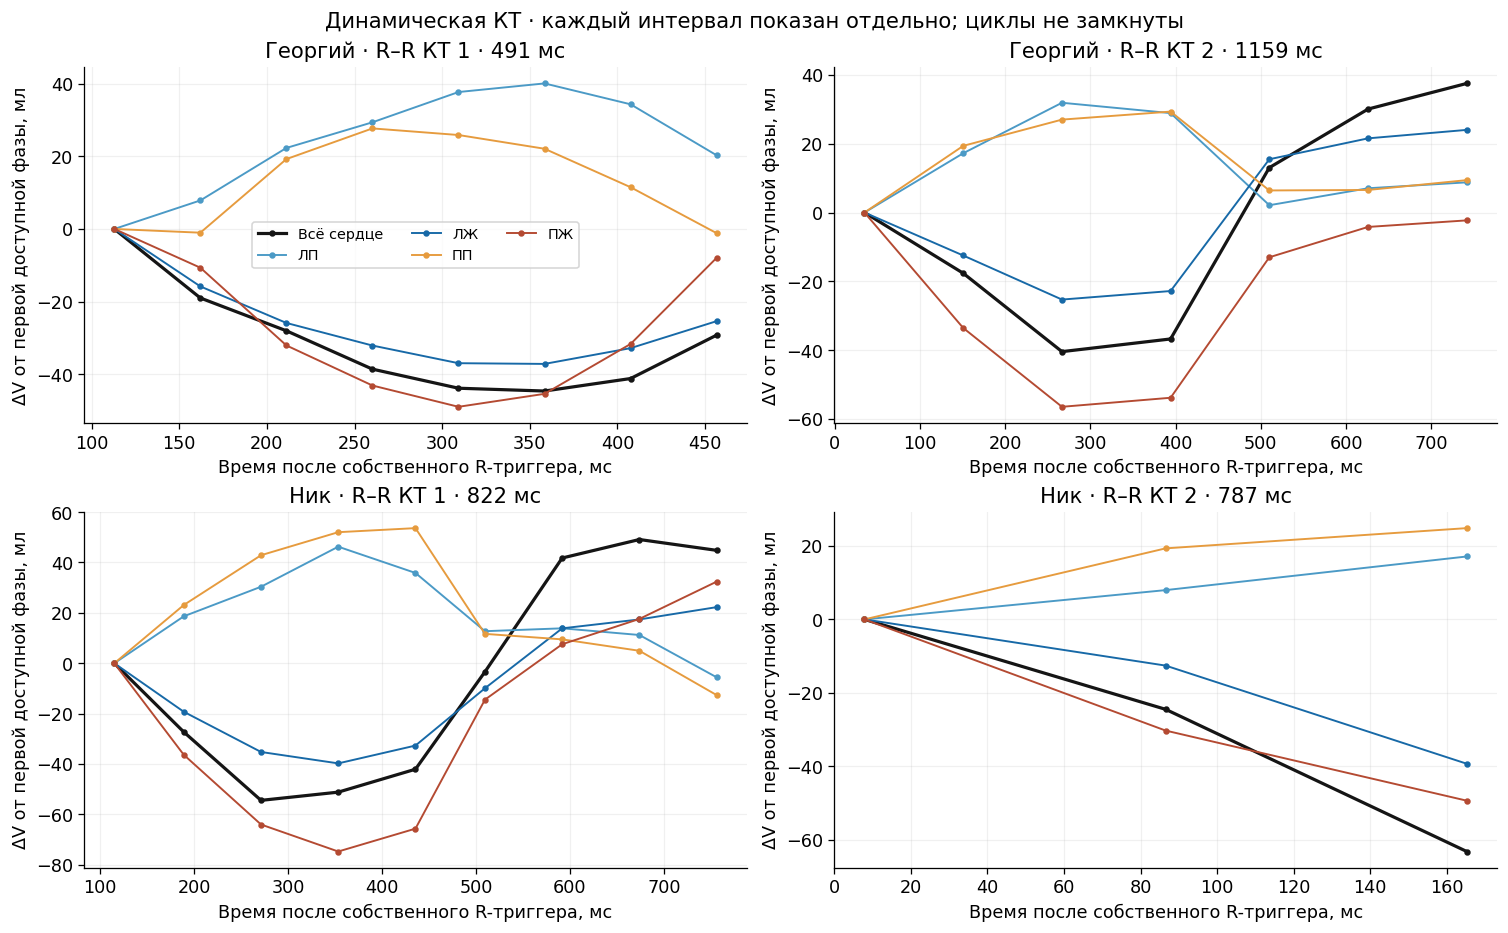

Участник,R–R КТ,"Длительность R–R, мс",Сравнение с объёмом всего сердца,Пар соседних фаз,Совпадение знаков,r межкадровых изменений,"RMSE тождества ΔVцел = ΔVкам, мл","Наблюдаемый размах камеры/суммы, мл","Размах всего сердца, мл"
Георгий,1,491,ЛЖ,7,7/7,0.974079,2.7156,37.1085,44.5645
Георгий,1,491,ПЖ,7,6/7,0.877603,8.32501,48.9028,44.5645
Георгий,1,491,ЛЖ + ПЖ,7,6/7,0.932199,13.258,85.8143,44.5645
Георгий,1,491,Сумма четырёх камер,7,5/7,0.757672,6.50273,22.321,44.5645
Георгий,2,1159,ЛЖ,6,6/6,0.981806,8.21256,49.3374,77.9845
Георгий,2,1159,ПЖ,6,6/6,0.975373,8.49419,56.4864,77.9845
Георгий,2,1159,ЛЖ + ПЖ,6,6/6,0.986358,17.5707,103.542,77.9845
Георгий,2,1159,Сумма четырёх камер,6,6/6,0.974057,9.8384,62.8033,77.9845
Ник,1,822,ЛЖ,8,6/8,0.966557,11.5303,62.0041,103.52
Ник,1,822,ПЖ,8,6/8,0.875644,12.9555,107.091,103.52


In [5]:
F.show_figure(S,4)
display(HTML(F.ct_table(S)))

**Рисунок 4.** Наблюдаемые изменения объёмов автоматических масок от первой
доступной фазы каждого интервала. Нули четырёх панелей имеют разные
референсные фазы. Линии соединяют доступные точки и не замыкают цикл.

**Наблюдение по маскам:** объём всего сердца связан с камерной динамикой,
но не равен изменению одной камеры. Для ЛЖ знаки совпадают у Георгия
в 7/7 и 6/6 пар; у Ника — в 6/8 и 2/2. При этом RMSE тождества составляет
соответственно 2,7; 8,2; 11,5 и 11,9 мл. Даже высокая описательная корреляция
не устраняет это различие. Несовпадение включает как реальную неоднородную
динамику, так и неопределённость автоматических масок; их вклады этим
расчётом не разделены. Единого проверенного перехода ΔVэкв → ΔVЛЖ не получено.

## 5. Что получится при переносе секущей на объёмную динамику КТ

Для каждого собственного КТ-интервала отдельно вычислена условная проекция
**ΔZобъём = kV · [Vцел(t) − Vцел(t₁)]**. Это перенос коэффициента сферы
на изменение маски всего сердца при фиксированном фоне, форме и центре.
Движение, деформация, изменение камерного наполнения при постоянном внешнем
объёме и пульсовые изменения ρ в этой проекции отсутствуют. Это не расчёт
динамической КТ методом FEM. Когда размах КТ превышает 0,10V₀, дополнительно
имеется экстраполяция за пределы объёмного теста. Даже внутри этого размаха
применимость секущей к другой форме и сессии не установлена.
В таблице отдельно подсчитаны КТ-фазы, абсолютный объём которых находится
вне 0,95–1,05V₀: малый межкадровый размах сам по себе не означает,
что исходное состояние входит в проверенную область. Объёмы КТ не смещались
для совмещения с V₀.

Пульс Scorpion прошёл полосу 0,7–12 Гц, а редкие КТ-фазы здесь не фильтруются:
восстановление непрерывного сигнала для такого фильтра потребовало бы
модели недостающих частей цикла. Поэтому сравниваются лишь порядки
размахов. Ни по точкам, ни по размаху не рассчитывается «ошибка измерения»
или точность УО. Начальные фазы, сердечные сокращения и сессии различны;
подбор фазового сдвига или масштаба для совмещения не выполнялся.

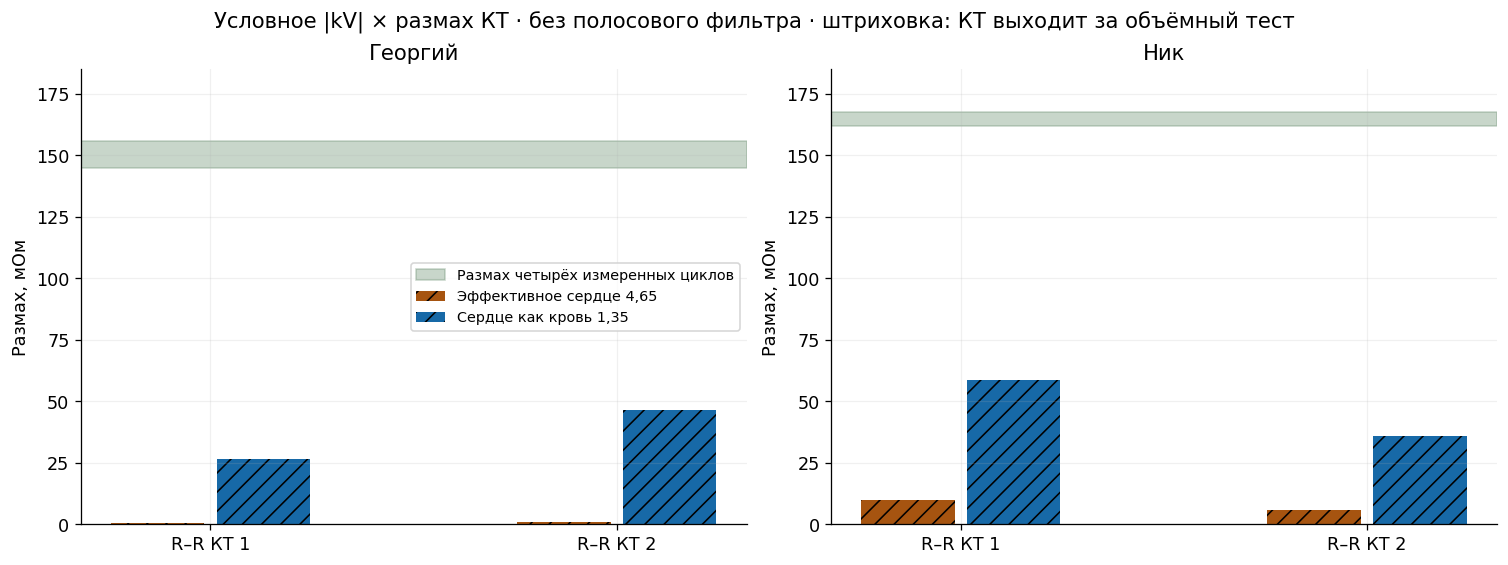

Участник,R–R КТ,Профиль,"Размах всего сердца на КТ, мл","Условный |kV| × размах КТ, мОм","Размах КТ больше 0,10V₀",КТ-фаз вне абсолютного диапазона сферы,Обратный переход монотонен в трёх точках
Георгий,1,"Эффективное сердце 4,65",44.5645,0.532174,Нет,4,Нет
Георгий,1,"Сердце как кровь 1,35",44.5645,26.5899,Нет,4,Да
Георгий,2,"Эффективное сердце 4,65",77.9845,0.931264,Да,5,Нет
Георгий,2,"Сердце как кровь 1,35",77.9845,46.5303,Да,5,Да
Ник,1,"Эффективное сердце 4,65",103.52,9.7881,Да,5,Да
Ник,1,"Сердце как кровь 1,35",103.52,58.7541,Да,5,Да
Ник,2,"Эффективное сердце 4,65",63.1948,5.97526,Да,3,Да
Ник,2,"Сердце как кровь 1,35",63.1948,35.8671,Да,3,Да


In [6]:
F.show_figure(S,5)
display(HTML(F.projection_table(S)))

**Рисунок 5.** Проекция наблюдаемого размаха КТ через объёмную секущую и
диапазон размахов четырёх измеренных ЭКГ-циклов. Штриховка отмечает
экстраполяцию по объёму. Значения относятся к разным сессиям и разной
частотной обработке, поэтому график служит проверкой масштаба постановки.
Проекция кровяного профиля даёт около 27–47 мОм у Георгия и 36–59 мОм
у Ника; это меньше 145–168 мОм измеренного пульса. В эффективном профиле
отклик ещё меньше, а у Георгия секущая не задаёт однозначной инверсии.

### Проверка направления изменений у Ника при явном допущении фазовой привязки

Для Ника выполнена дополнительная описательная проверка: одинаковые доли
собственного R–R условно сопоставлены между сессиями КТ и Scorpion.
Четыре измеренных цикла по отдельности интерполированы к сохранённым
процентам КТ-фаз. Подбор задержки, смена знака и амплитудная подгонка
не выполнялись. Начальная КТ-фаза служит одинаковой точкой отсчёта
для каждого сравниваемого контраста. Это проверяемое допущение переноса,
а не установленная синхронность. Полосовая обработка также различается.

У Георгия равномерное сопоставление долей короткого и длинного R–R не
применено из-за неразрешённого гейтинга. Его модельная полярность проверена,
но согласие пульса с механической фазой по этим КТ-триггерам не установлено.
Для Ярослава фазовая проверка по КТ недоступна.

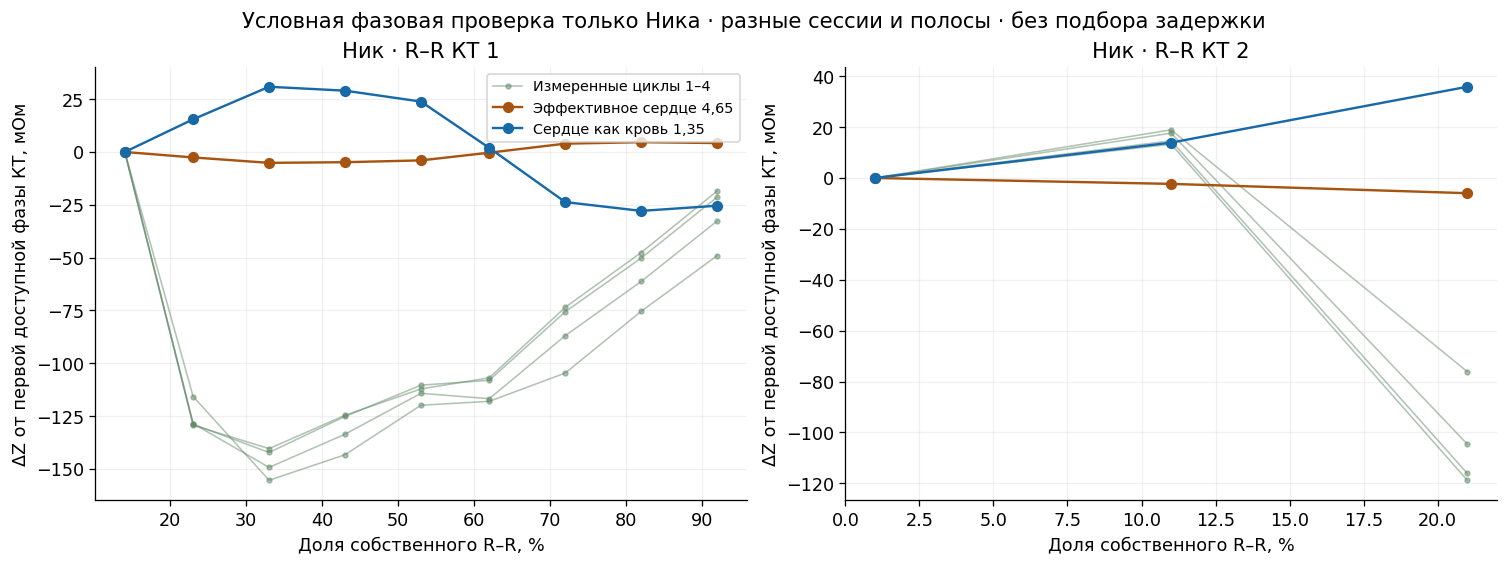

Участник,R–R КТ,Цикл Scorpion,Профиль,Совпадение знаков соседних изменений,Привязка фаз проверена,Частотная обработка совпадает
Ник,1,1,"Эффективное сердце 4,65",7/8,Нет,Нет
Ник,1,2,"Эффективное сердце 4,65",7/8,Нет,Нет
Ник,1,3,"Эффективное сердце 4,65",6/8,Нет,Нет
Ник,1,4,"Эффективное сердце 4,65",7/8,Нет,Нет
Ник,1,1,"Сердце как кровь 1,35",1/8,Нет,Нет
Ник,1,2,"Сердце как кровь 1,35",1/8,Нет,Нет
Ник,1,3,"Сердце как кровь 1,35",2/8,Нет,Нет
Ник,1,4,"Сердце как кровь 1,35",1/8,Нет,Нет
Ник,2,1,"Эффективное сердце 4,65",1/2,Нет,Нет
Ник,2,2,"Эффективное сердце 4,65",1/2,Нет,Нет


In [7]:
F.show_figure(S,6)
display(HTML(F.phase_table(S)))

**Рисунок 6.** Условное сопоставление по доле R–R только Ника. В первом
КТ-интервале направление соседних изменений измеренного пульса совпадает
с объёмной проекцией эффективного профиля в 6–7 из 8 пар, а кровяного —
в 1–2 из 8. Во втором интервале доступно лишь две пары: для обоих профилей
совпадает одна. Эти счётчики не являются вероятностью правильной модели,
точностью классификации или подтверждением причинной связи.

Таким образом, кровяной профиль увеличивает модельный размах, но в данном
условном фазовом сопоставлении не улучшает направление ответа. Выбрать
индивидуальный тканевой профиль только по такому совпадению нельзя:
фазовый перенос, фильтрация и выделение сердечного компонента не проверены.

### Что установлено и что передаётся дальше

Измеренный пульс и рассчитанная объёмная чувствительность сопоставлены
для трёх участников без подбора знака, усиления или задержки. Простая
инверсия однородной сферы с неподвижным центром не получила подтверждения:
проверенный объёмный диапазон недостаточен, а направление ответа зависит
от материальной постановки. Динамическая КТ дополнительно показывает,
почему изменение объёма целого сердца нельзя автоматически называть УО ЛЖ.

Передаются четыре измеренных интервала на участника, секущие двух
материальных профилей с отдельным контролем q и раздельные камерные
сопоставления по каждому доступному R–R КТ. Они предназначены для
исследовательской проверки, а не для вычисления валидированных функций сердца.

Тканевая коррекция по поясной ЭИТ/PulmoVista — самостоятельное звено основной
методики. Здесь её параметры не заданы и поправка не вычислена; исходный
пульс не назван выделенным сердечным компонентом. Применять коэффициенты
из другой сессии как синхронную поправку нельзя без проверки переноса.
Для следующего перехода нужны проверенные тканевые вклады и электрическая
модель, различающая камерное наполнение, форму и положение; добавление одной
произвольной поправки амплитуды текущий отрицательный тест не закрывает.

Для Ярослава выполнена импедансная часть; камерная остаётся недоступной
до появления собственной динамической КТ. Анатомическая ошибка масок,
ошибка установки электродов, межсессионная воспроизводимость и шумовая
модель не оценены численно. Сходимость электрической сетки не установлена.
Эти неизвестные не заменены нулём или доверительным интервалом.

### Происхождение и воспроизведение

Все входные агрегаты, первичные выбранные записи, кэши, разметка и модельные
отчёты проверяются по SHA-256. Для Георгия привязка записи 003 заново сверена
с действующим подтверждённым протоколом: весь файл протокола изменялся
после сохранения артефакта отображения. Назначения других записей из этого
артефакта сюда не переносились. Разметка и исходные данные не изменены.

Связанные результаты: [измерения и индивидуальная FEM-проверка](33.43_Индивидуальная_КТ_FEM_проверка_трёх_участников_Scorpion.html),
[КТ-камеры и временные интервалы](../cardiac_4d_segmentation/21.03_Вычитание_крови_и_объёмы_камер_RR.html).
Расчёт воспроизводит генератор `build_measured_pulse_report.py --execute --html`
из папки этого отчёта; он читает сохранённые локальные входы и не запускает FEM.
Читательский HTML содержит изображения и свёрнутые таблицы без исходного кода.

In [8]:
display(HTML(F.table(S['sources']+[S['analysis'],S['generator']], 'Таблица 6. Относительные источники и SHA-256')))

Относительный источник,SHA-256
Colab Notebooks/cardiac_4d_segmentation/analyze_subtraction_and_rr.py,e0059aa74f0c6a34bf57cb9b5a3072df009bc1927ff5d5c9c9f143843eb90c07
Colab Notebooks/cardiac_4d_segmentation/heart_rr_analysis/chamber_volumes_by_rr.csv,01b3d836c43b8accb95013bca3b961aa25dfdadc1ff2f3edca7c11ae35168ba8
Colab Notebooks/cardiac_4d_segmentation/heart_rr_analysis/rr_and_subtraction_summary.json,fb55bb5717cc0253823b733e1ce0c720eec73f499d1b660fca694e17fbedd27e
Colab Notebooks/scorpion_v2/_assets/fem_smart_20261026.summary.json,86e3b45a16a978418822f043c10694887e8372943beae8b7f5679ea65f1b3fd9
Colab Notebooks/scorpion_v2/build_scorpion_fem_smart_report.py,ce5ff02888242e3f4fedc70991f3251ef6637fbb6fb964118659593fbd496ce3
Colab Notebooks/scorpion_v2/lateral_pilot.py,aab1bc096773bc2df7f96a3e0d46a327a3b51f65156fcae6bc3ecfb5844468e6
Colab Notebooks/scorpion_v2/scorpion_protocol.py,85e49b1ed729df29573ee8e0b300099f3e55354b0c9b49321ce8263214b9a1dc
Colab Notebooks/scorpion_v2/scorpion_qc.py,9474b069f4e7adb79608627b942edabfe4798faa5557544728883b1458c14edf
Colab Notebooks/scorpion_v2/session_20261022.py,0f5cd5f9f34ba156bbc82832c4628b549f6843644b73ff7a3e2d36590436af0c
Experiments/scorpion_20261022/annotations/session_1140/candidate_annotations.local.json,47e46e620f45dbbabe03187992ccfd6b656fbecf04791d26e513e76a82e1fb4a
